# Model Evaluation and Results

This notebook compares benchmark and machine-learning GDP nowcasts over the common out-of-sample period from 2017Q1 to 2026Q1.

Models are evaluated using RMSE, MAE and directional accuracy, with additional analysis of forecast performance across the M1, M2 and M3 information sets and during the COVID-19 period.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_squared_error, mean_absolute_error

In [2]:
naive_results = pd.read_csv(
    "../data/processed/naive_forecasts.csv"
)

ar_results = pd.read_csv(
    "../data/processed/ar_forecasts.csv"
)

ridge_m1_results = pd.read_csv(
    "../data/processed/ridge_m1_forecasts.csv"
)

ridge_m2_results = pd.read_csv(
    "../data/processed/ridge_m2_forecasts.csv"
)

ridge_m3_results = pd.read_csv(
    "../data/processed/ridge_m3_forecasts.csv"
)

rf_m1_results = pd.read_csv(
    "../data/processed/rf_m1_forecasts.csv"
)

rf_m2_results = pd.read_csv(
    "../data/processed/rf_m2_forecasts.csv"
)

rf_m3_results = pd.read_csv(
    "../data/processed/rf_m3_forecasts.csv"
)

gb_m1_results = pd.read_csv(
    "../data/processed/gb_m1_forecasts.csv"
)

gb_m2_results = pd.read_csv(
    "../data/processed/gb_m2_forecasts.csv"
)

gb_m3_results = pd.read_csv(
    "../data/processed/gb_m3_forecasts.csv"
)

In [3]:
forecast_datasets = [
    naive_results,
    ar_results,
    ridge_m1_results,
    ridge_m2_results,
    ridge_m3_results,
    rf_m1_results,
    rf_m2_results,
    rf_m3_results,
    gb_m1_results,
    gb_m2_results,
    gb_m3_results
]

for df in forecast_datasets:
    df["quarter"] = pd.PeriodIndex(
        df["quarter"],
        freq="Q"
    )

In [4]:
for df in forecast_datasets:
    print(
        df["model"].iloc[0],
        df["info_set"].iloc[0],
        len(df),
        df["quarter"].min(),
        df["quarter"].max()
    )

Naive nan 37 2017Q1 2026Q1
AR(1) nan 37 2017Q1 2026Q1
Ridge M1 37 2017Q1 2026Q1
Ridge M2 37 2017Q1 2026Q1
Ridge M3 37 2017Q1 2026Q1
Random Forest M1 37 2017Q1 2026Q1
Random Forest M2 37 2017Q1 2026Q1
Random Forest M3 37 2017Q1 2026Q1
Gradient Boosting M1 37 2017Q1 2026Q1
Gradient Boosting M2 37 2017Q1 2026Q1
Gradient Boosting M3 37 2017Q1 2026Q1


In [5]:
all_results = pd.concat(
    forecast_datasets,
    ignore_index=True
)

print("Total forecast rows:", len(all_results))
display(all_results.head())
display(all_results.tail())

Total forecast rows: 407


,quarter,model,info_set,actual,prediction,alpha
0,2017Q1,Naive,NaN,1.0,0.6,NaN
1,2017Q2,Naive,NaN,0.9,1.0,NaN
2,2017Q3,Naive,NaN,0.7,0.9,NaN
3,2017Q4,Naive,NaN,0.8,0.7,NaN
4,2018Q1,Naive,NaN,0.1,0.8,NaN


,quarter,model,info_set,actual,prediction,alpha
402,2025Q1,Gradient Boosting,M3,0.6,0.446310,NaN
403,2025Q2,Gradient Boosting,M3,0.2,0.448443,NaN
404,2025Q3,Gradient Boosting,M3,0.1,0.445043,NaN
405,2025Q4,Gradient Boosting,M3,0.1,0.437265,NaN
406,2026Q1,Gradient Boosting,M3,0.6,0.432774,NaN


In [ ]:
all_results["model_label"] = np.where(
    all_results["info_set"].isna(),
    all_results["model"],
    all_results["model"] + " " + all_results["info_set"]
)

display(
    all_results[
        ["quarter", "model_label", "actual", "prediction"]
    ].head(15)
)

,quarter,model_label,actual,prediction
0,2017Q1,Naive,1.0,0.6
1,2017Q2,Naive,0.9,1.0
2,2017Q3,Naive,0.7,0.9
3,2017Q4,Naive,0.8,0.7
4,2018Q1,Naive,0.1,0.8
5,2018Q2,Naive,0.2,0.1
6,2018Q3,Naive,0.3,0.2
7,2018Q4,Naive,0.1,0.3
8,2019Q1,Naive,0.5,0.1
9,2019Q2,Naive,0.2,0.5


## 1. Evaluation Metrics

Forecast performance is evaluated using RMSE, MAE and directional accuracy over the common out-of-sample period from 2017Q1 to 2026Q1.

In [16]:
def calculate_metrics(results):

    rmse = np.sqrt(
        mean_squared_error(
            results["actual"],
            results["prediction"]
        )
    )

    mae = mean_absolute_error(
        results["actual"],
        results["prediction"]
    )

    directional_accuracy = np.mean(
        np.sign(results["actual"]) ==
        np.sign(results["prediction"])
    )

    return pd.Series({
        "RMSE": rmse,
        "MAE": mae,
        "DA": directional_accuracy
    })

In [23]:
metrics_table = (
    all_results
    .groupby("model_label")
    .apply(calculate_metrics, include_groups=False)
    .reset_index()
)


metrics_table["DA"] = metrics_table["DA"] * 100


oos_r2_values = []

for model_label in metrics_table["model_label"]:

    model_results = all_results[
        all_results["model_label"] == model_label
    ]

    model_sse = np.sum(
        (model_results["actual"] - model_results["prediction"]) ** 2
    )

    oos_r2 = 1 - (model_sse / naive_sse)

    oos_r2_values.append(oos_r2)


metrics_table["OOS_R2"] = np.array(oos_r2_values) * 100


metrics_table = (
    metrics_table
    .sort_values("RMSE")
    .reset_index(drop=True)
)


display(
    metrics_table.round({
        "RMSE": 3,
        "MAE": 3,
        "DA": 1,
        "OOS_R2": 1,
    })
)

,model_label,RMSE,MAE,DA,OOS_R2
0,Ridge M3,3.929,1.720,73.0,71.6
1,Gradient Boosting M3,4.266,1.634,78.4,66.5
2,Ridge M2,4.388,1.606,81.1,64.6
3,Ridge M1,4.579,1.655,64.9,61.4
4,Random Forest M3,4.619,1.556,75.7,60.8
5,Random Forest M2,5.180,1.998,70.3,50.7
6,Gradient Boosting M2,5.352,2.020,70.3,47.3
7,Random Forest M1,6.298,2.591,70.3,27.1
8,Gradient Boosting M1,6.689,2.437,70.3,17.7
9,Naive,7.374,2.627,78.4,0.0


In [32]:
from pathlib import Path

Path("../data/results").mkdir(exist_ok=True)

In [33]:
metrics_table.round({
    "RMSE": 3,
    "MAE": 3,
    "DA": 1,
    "OOS_R2": 1
}).to_csv(
    "../data/results/model_performance.csv",
    index=False
)

### Key Results

Ridge M3 achieves the lowest RMSE and the highest out-of-sample R², reducing squared forecast errors by 71.6% relative to the Naive benchmark. Random Forest M3 records the lowest MAE, while Ridge M2 achieves the highest directional accuracy.

Forecast performance improves from M1 to M3 across all three model families in terms of RMSE, indicating that additional within-quarter information improves GDP nowcasts. The machine-learning models substantially outperform the simple benchmarks, but do not consistently outperform Ridge regression.

The relatively high directional accuracy of the Naive and AR(1) benchmarks also shows that directional accuracy should be interpreted alongside magnitude-based forecast metrics.

## 2. Forecast Performance Across Information Sets

RMSE is compared across M1, M2 and M3 to assess whether forecast accuracy improves as additional within-quarter information becomes available.

In [25]:
info_set_rmse = metrics_table[
    metrics_table["model_label"].str.contains(
        "Ridge|Random Forest|Gradient Boosting"
    )][["model_label", "RMSE"]].copy()

info_set_rmse["model"] = (
    info_set_rmse["model_label"]
    .str.replace(r" M[123]$", "", regex=True)
)

info_set_rmse["info_set"] = (
    info_set_rmse["model_label"]
    .str.extract(r"(M[123])$")
)

info_set_rmse = info_set_rmse.sort_values(
    ["model", "info_set"]
)

display(info_set_rmse)

,model_label,RMSE,model,info_set
8,Gradient Boosting M1,6.688555,Gradient Boosting,M1
6,Gradient Boosting M2,5.352145,Gradient Boosting,M2
1,Gradient Boosting M3,4.266472,Gradient Boosting,M3
7,Random Forest M1,6.298161,Random Forest,M1
5,Random Forest M2,5.179959,Random Forest,M2
4,Random Forest M3,4.619333,Random Forest,M3
3,Ridge M1,4.578794,Ridge,M1
2,Ridge M2,4.387510,Ridge,M2
0,Ridge M3,3.929182,Ridge,M3


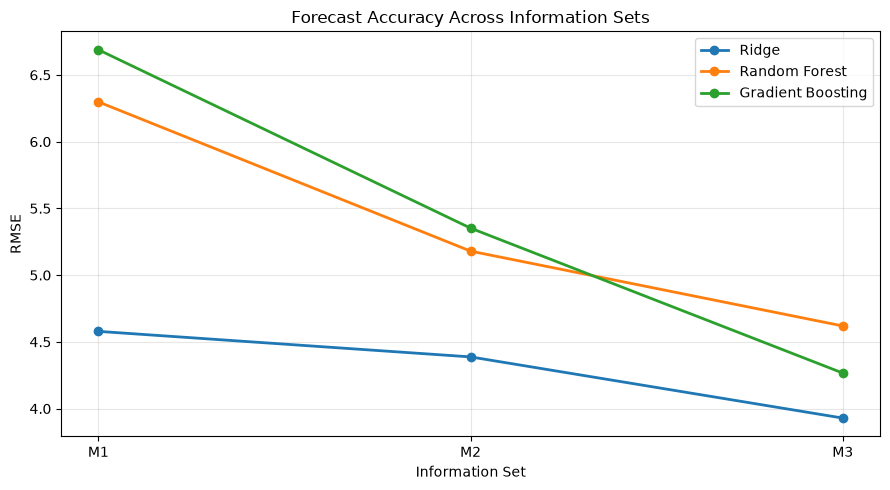

In [30]:
plt.figure(figsize=(9, 5))

for model in ["Ridge", "Random Forest", "Gradient Boosting"]:

    model_data = info_set_rmse[
        info_set_rmse["model"] == model
    ]

    plt.plot(
        model_data["info_set"],
        model_data["RMSE"],
        marker="o",
        linewidth=2,
        label=model
    )

plt.xlabel("Information Set")
plt.ylabel("RMSE")
plt.title("Forecast Accuracy Across Information Sets")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "../figures/rmse_by_information_set.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 3. Actual vs Predicted GDP Growth

Actual quarterly GDP growth is compared with forecasts from the main benchmark and the best-performing M3 specifications to examine forecast behaviour over time.

In [27]:
plot_models = [
    "Naive",
    "Ridge M3",
    "Random Forest M3",
    "Gradient Boosting M3"
]

forecast_plot = all_results[
    all_results["model_label"].isin(plot_models)].copy()

actual_plot = (
    all_results[
        ["quarter", "actual"]]
    .drop_duplicates("quarter")
    .sort_values("quarter")
)

forecast_plot["quarter_date"] = (forecast_plot["quarter"].dt.to_timestamp())

actual_plot["quarter_date"] = (actual_plot["quarter"].dt.to_timestamp())

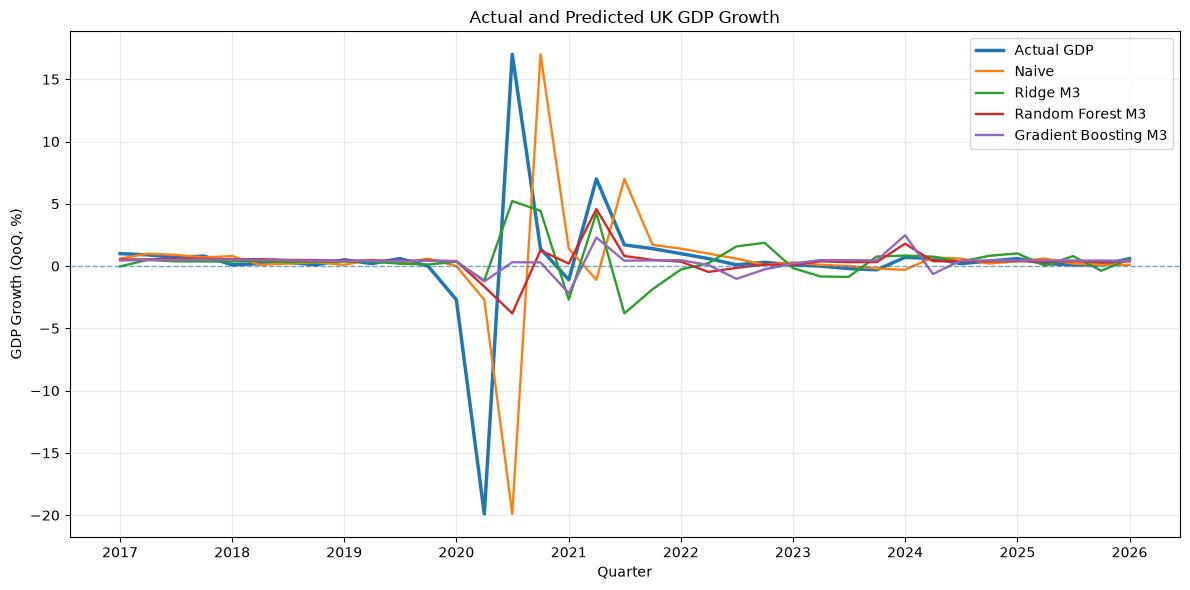

In [29]:
plt.figure(figsize=(12, 6))

plt.plot(
    actual_plot["quarter_date"],
    actual_plot["actual"],
    linewidth=2.5,
    label="Actual GDP"
)

for model in plot_models:

    model_data = forecast_plot[
        forecast_plot["model_label"] == model].sort_values("quarter_date")

    plt.plot(
        model_data["quarter_date"],
        model_data["prediction"],
        linewidth=1.7,
        label=model
    )

plt.axhline(
    y=0,
    linewidth=1,
    linestyle="--",
    alpha=0.6
)

plt.xlabel("Quarter")
plt.ylabel("GDP Growth (QoQ, %)")
plt.title("Actual and Predicted UK GDP Growth")

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.savefig(
    "../figures/actual_vs_predicted_gdp.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## 4. COVID vs Non-COVID Performance

To assess the impact of the COVID-19 shock on forecast performance, RMSE is compared across the full evaluation sample, the COVID period (2020Q1–2021Q4), and the remaining non-COVID quarters.

This comparison helps distinguish general forecasting performance from errors driven by the exceptional volatility during the pandemic.

In [34]:
covid_start = pd.Period("2020Q1", freq="Q")
covid_end = pd.Period("2021Q4", freq="Q")

covid_performance = []

for model_label in all_results["model_label"].unique():

    model_data = all_results[
        all_results["model_label"] == model_label
    ].copy()

    covid_data = model_data[
        (model_data["quarter"] >= covid_start) &
        (model_data["quarter"] <= covid_end)
    ]

    non_covid_data = model_data[
        (model_data["quarter"] < covid_start) |
        (model_data["quarter"] > covid_end)
    ]

    full_rmse = np.sqrt(
        mean_squared_error(
            model_data["actual"],
            model_data["prediction"]
        )
    )

    covid_rmse = np.sqrt(
        mean_squared_error(
            covid_data["actual"],
            covid_data["prediction"]
        )
    )

    non_covid_rmse = np.sqrt(
        mean_squared_error(
            non_covid_data["actual"],
            non_covid_data["prediction"]
        )
    )

    covid_performance.append({
        "model_label": model_label,
        "Full Sample": full_rmse,
        "COVID": covid_rmse,
        "Non-COVID": non_covid_rmse
    })

covid_performance = pd.DataFrame(covid_performance)

covid_performance = covid_performance.sort_values(
    "Full Sample"
).reset_index(drop=True)

display(covid_performance.round(3))

,model_label,Full Sample,COVID,Non-COVID
0,Ridge M3,3.929,8.362,0.639
1,Gradient Boosting M3,4.266,9.109,0.581
2,Ridge M2,4.388,9.399,0.437
3,Ridge M1,4.579,9.825,0.347
4,Random Forest M3,4.619,9.901,0.424
5,Random Forest M2,5.180,10.835,1.359
6,Gradient Boosting M2,5.352,11.226,1.336
7,Random Forest M1,6.298,13.172,1.657
8,Gradient Boosting M1,6.689,14.285,0.886
9,Naive,7.374,15.844,0.368


In [35]:
covid_performance.round({
    "Full Sample": 3,
    "COVID": 3,
    "Non-COVID": 3
}).to_csv(
    "../data/results/covid_vs_non_covid_performance.csv",
    index=False
)

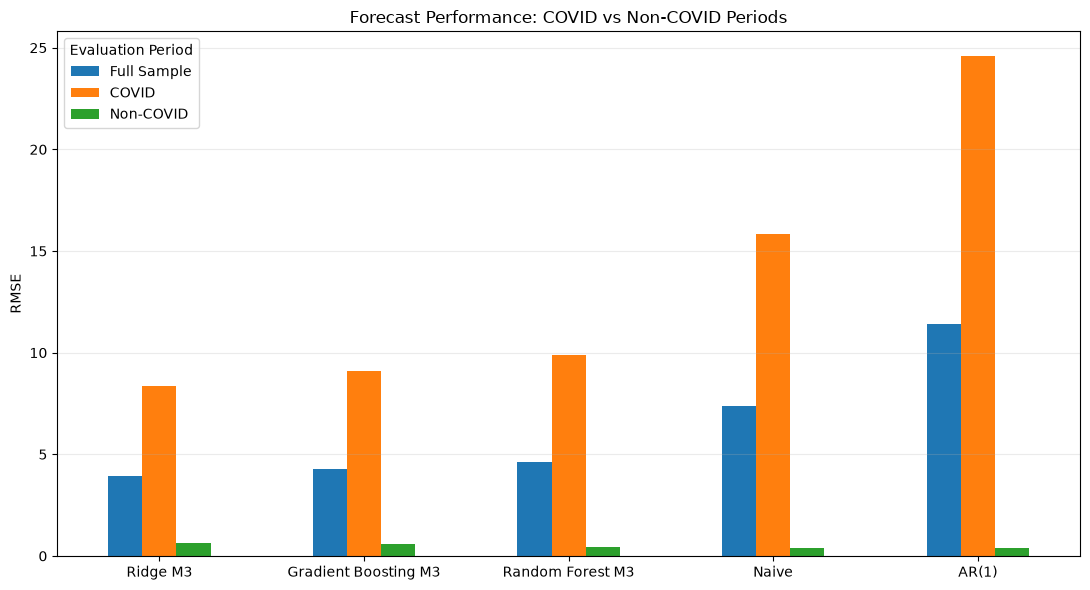

In [36]:
selected_models = [
    "Naive",
    "AR(1)",
    "Ridge M3",
    "Random Forest M3",
    "Gradient Boosting M3"
]

covid_plot = covid_performance[
    covid_performance["model_label"].isin(selected_models)
].copy()

covid_plot = covid_plot.set_index("model_label")[
    ["Full Sample", "COVID", "Non-COVID"]
]

ax = covid_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

ax.set_title("Forecast Performance: COVID vs Non-COVID Periods")
ax.set_xlabel("")
ax.set_ylabel("RMSE")
ax.tick_params(axis="x", rotation=0)

plt.legend(title="Evaluation Period")
plt.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    "../figures/covid_vs_non_covid_rmse.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Forecast errors increase sharply during the COVID-19 period for all models, confirming that aggregate RMSE is heavily influenced by a small number of extreme quarters. Outside the pandemic period, forecast errors are substantially smaller across all specifications.

The AR(1) benchmark is particularly sensitive to the COVID shock, while the indicator-based M3 models remain considerably more stable during the disruption.

## 5. Forecast Errors Over Time

Forecast errors are examined over time to identify periods in which model performance deteriorates and to assess whether large aggregate errors are concentrated around major economic shocks.

Forecast error is defined as:

$$
e_t = y_t - \hat{y}_t
$$

where positive values indicate underprediction and negative values indicate overprediction.

In [37]:
error_models = [
    "Naive",
    "AR(1)",
    "Ridge M3",
    "Random Forest M3",
    "Gradient Boosting M3"
]

error_plot = all_results[
    all_results["model_label"].isin(error_models)
].copy()

error_plot["error"] = (
    error_plot["actual"] - error_plot["prediction"]
)

error_plot["quarter_date"] = (
    error_plot["quarter"].dt.to_timestamp()
)

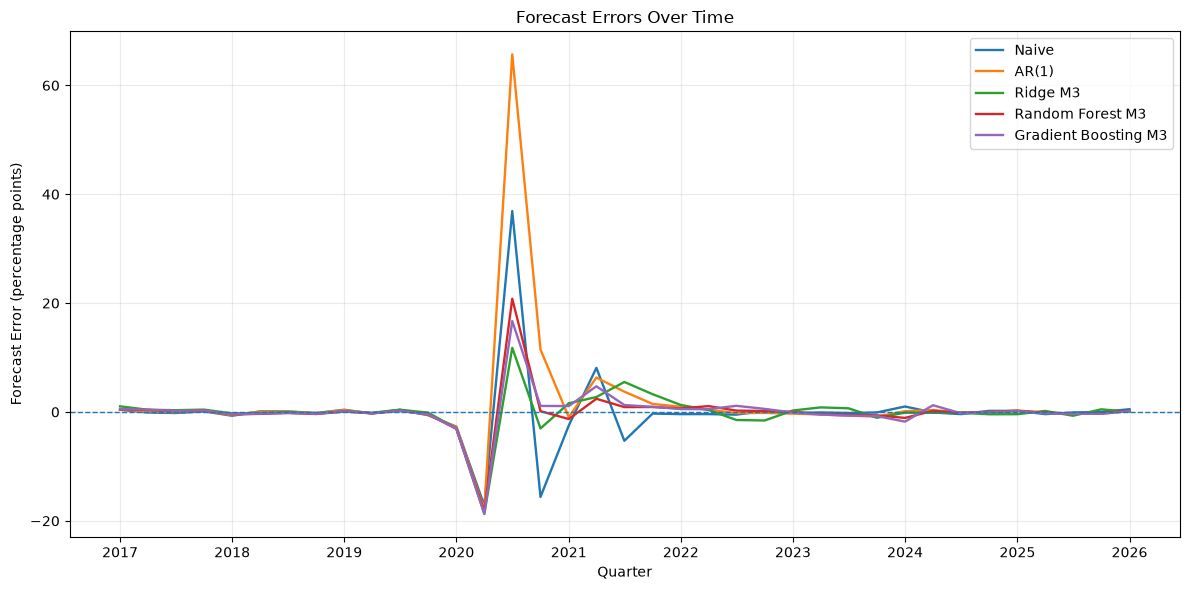

In [38]:
plt.figure(figsize=(12, 6))

for model in error_models:

    model_data = error_plot[
        error_plot["model_label"] == model].sort_values("quarter_date")

    plt.plot(
        model_data["quarter_date"],
        model_data["error"],
        linewidth=1.7,
        label=model
    )

plt.axhline(
    y=0,
    linewidth=1,
    linestyle="--"
)

plt.xlabel("Quarter")
plt.ylabel("Forecast Error (percentage points)")
plt.title("Forecast Errors Over Time")

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()

plt.savefig(
    "../figures/forecast_errors_over_time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Forecast errors are strongly concentrated around the COVID-19 shock. All models fail to anticipate the unprecedented contraction and subsequent rebound, but the simple benchmarks are particularly affected. AR(1) produces the largest error during the rebound as the extreme previous-quarter contraction is propagated into its subsequent forecast.

Outside the pandemic disruption, forecast errors are substantially smaller and remain concentrated around zero.

## 6. Cumulative Forecast Error

Cumulative absolute forecast error is used to compare how forecast errors accumulate over the evaluation period. A slower increase indicates more consistently accurate forecasts.

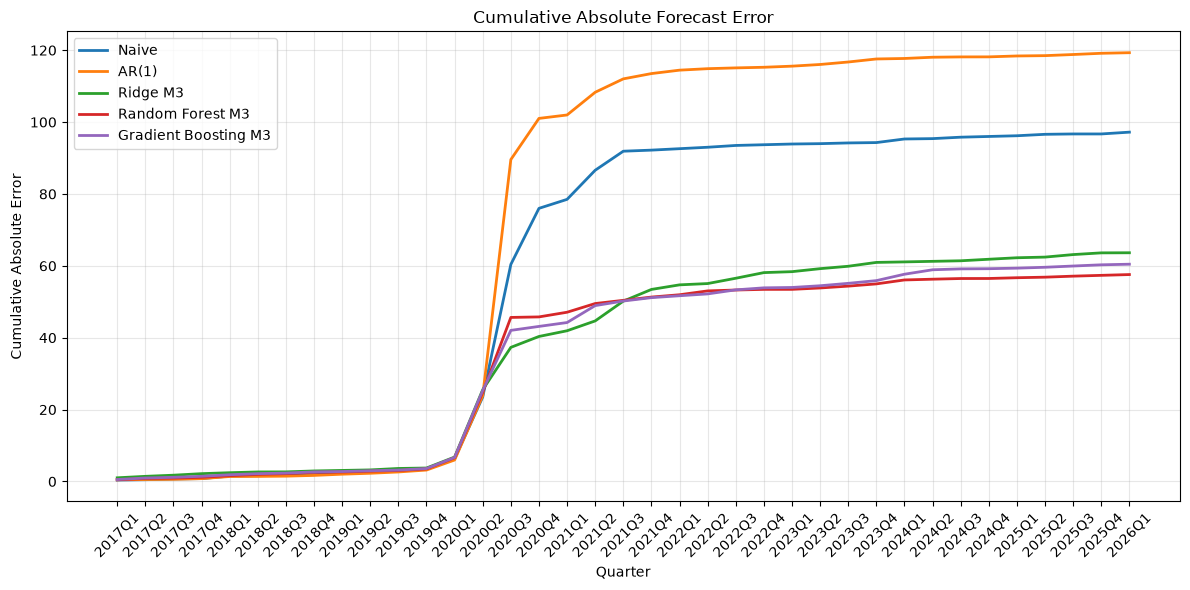

In [39]:
selected_models = [
    "Naive",
    "AR(1)",
    "Ridge M3",
    "Random Forest M3",
    "Gradient Boosting M3"
]

cumulative_data = all_results[
    all_results["model_label"].isin(selected_models)
].copy()

cumulative_data["absolute_error"] = np.abs(
    cumulative_data["actual"] - cumulative_data["prediction"]
)

cumulative_data["cumulative_absolute_error"] = (
    cumulative_data
    .groupby("model_label")["absolute_error"]
    .cumsum()
)

plt.figure(figsize=(12, 6))

for model in selected_models:
    
    model_data = cumulative_data[
        cumulative_data["model_label"] == model
    ]
    
    plt.plot(
        model_data["quarter"].astype(str),
        model_data["cumulative_absolute_error"],
        label=model,
        linewidth=2
    )

plt.title("Cumulative Absolute Forecast Error")
plt.xlabel("Quarter")
plt.ylabel("Cumulative Absolute Error")

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../figures/cumulative_absolute_error.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

The cumulative error paths show that most forecast deterioration is concentrated around the COVID-19 shock. AR(1) and the Naive benchmark accumulate substantially larger errors during this period, while Ridge, Random Forest and Gradient Boosting remain considerably more robust. Outside the pandemic period, cumulative errors increase only gradually.